# Porównania na spotkanie: co badamy i przykładowe wyniki

Notatnik puszcza **krótkie przebiegi bez GUI** (4 h symulacji od poniedziałku 8:00, kilka seedów,
równolegle) przez `src/experiments/build.py` i `record.py`, czyli te same parametry co pasek
boczny wizualizacji. Całość liczy się kilka minut; wyniki trafiają do `output/porownania/*.csv`
i przy ponownym uruchomieniu są wczytywane, a nie liczone od nowa.

Wyniki są **przykładowe** (3–5 seedów, 4 h zamiast doby). Pełne liczenie robi runner scenariuszy
(`make scenarios`). Uzasadnienie wszystkich ustawień: `docs/decyzje_dane_olist.md`, sekcja 10.

**Skala obciążenia (suwak „Natężenie”)**: prawdziwy Olist to ok. 123 zamówienia dziennie, za mało
dla magazynu Kiva, więc:

| Natężenie | Znaczenie | Zamówień/h (8:00 → 12:00) |
| --- | --- | --- |
| ×1 | zwykły dzień (Olist ×10, jak w scenariuszach) | 38 → 90 |
| ×5 | wzmożony ruch (połowa Black Friday) | 190 → 450 |
| ×9,5 | szczyt: Black Friday 2017 (1166 zamówień wobec ~123 w średni dzień) | 360 → 855 |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.experiments.build import LAYOUTS, olist_stats
from src.experiments.compare import layout_geometry, run_grid, summary
from src.plotting.style import CATEGORICAL, INK_SECONDARY, style

style()
OUT = ROOT / "output" / "porownania"
JOBS = 4  # procesy równolegle; zmniejsz na słabszym komputerze
pd.set_option("display.precision", 1)
assert olist_stats() is not None, "Brak danych Olist: uv run data/download_olist.py"

LOAD = {1.0: "zwykły dzień ×1", 5.0: "wzmożony ×5", 9.5: "Black Friday ×9,5"}


def bars(ax, table, group, series, metric, labels=None, colors=None):
    """Grouped bars with 95% intervals: one group per value of ``group``."""
    groups = list(dict.fromkeys(table[group]))
    names = list(dict.fromkeys(table[series]))
    width = 0.8 / len(names)
    for i, name in enumerate(names):
        part = table[table[series] == name].set_index(group).reindex(groups)
        x = np.arange(len(groups)) + (i - (len(names) - 1) / 2) * width
        ax.bar(x, part[metric], width, yerr=part[metric + "_ci"], capsize=3,
               color=(colors or CATEGORICAL)[i], label=(labels or {}).get(name, name))
    ax.set_xticks(np.arange(len(groups)), [(LOAD if group == "volume" else {}).get(g, g) for g in groups])
    ax.grid(axis="x", visible=False)

## 0. Czy model w ogóle działa przy dużym ruchu? (zakleszczenia przed i po poprawce)

Najpierw sprawdzenie, czy porównania da się w ogóle przeprowadzić. „Stare” zasady ruchu to stan
`main` sprzed poprawki, „nowe” to `TrafficParams` (puste roboty pod regałami, kierunki w alejkach,
limit kolejki do stanowiska, wolne pole przed stanowiskiem, omijanie stojących robotów, zjazd
z ładowarki, stanowisko najbliższe regałowi). Liczymy odsetek przebiegów zatrzymanych przez
zakleszczenie.

Od 23.11 układ `kiva_standard` ma rząd postojowy na dole i ładowarki na końcach poprzecznych alejek
(sekcja 12 w `docs/decyzje_dane_olist.md`). Stare zasady zakleszczają się w nim już w zwykły dzień,
bo robot bez przejazdu pod regałami utyka w pustym slocie po regale; to ten sam błąd, który nowe
zasady usuwają regułą `leave_rack_slots`. Wcześniejsze 0% przy ×1 dla starych zasad było liczone
w poprzednim układzie.


traffic,old,new
volume,,
1.0,50.0,0.0
2.0,50.0,0.0
5.0,100.0,0.0
9.5,100.0,0.0


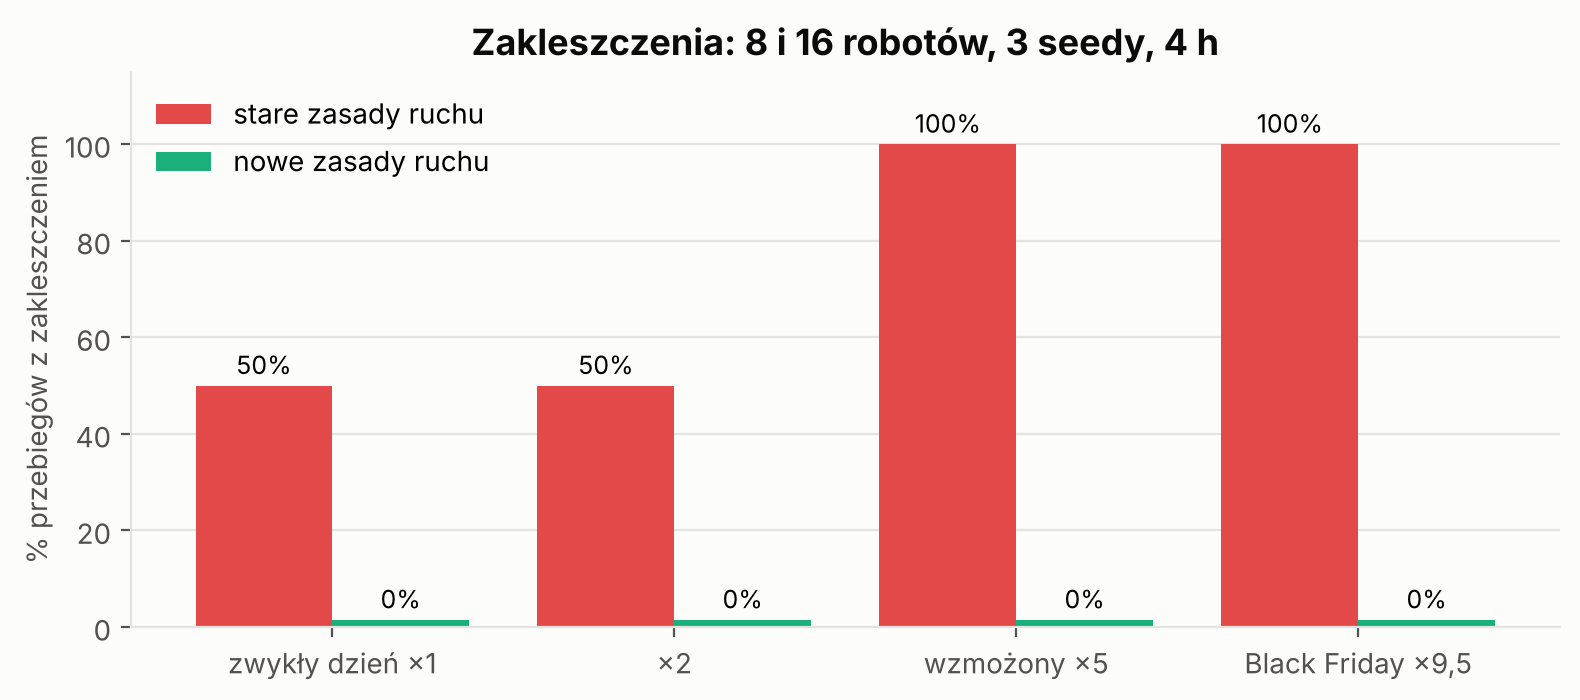

In [2]:
specs = [dict(num_robots=r, volume=v, seed=s, traffic=t)
         for t in ("old", "new") for r in (8, 16) for v in (1.0, 2.0, 5.0, 9.5) for s in (1, 2, 3)]
e0 = run_grid(specs, OUT / "e0_zakleszczenia.csv", jobs=JOBS)
e0["zakleszczenie"] = e0["status"].isin(["deadlock", "livelock"])
t0 = e0.groupby(["traffic", "volume"])["zakleszczenie"].mean().mul(100).unstack(0)[["old", "new"]]

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(t0))
# Słupek o wartości 0 % jest niewidoczny, więc rysujemy co najmniej cienką kreskę (1,5 pkt)
# i podpisujemy każdy słupek prawdziwą wartością.
for offset, col, colour, label in ((-0.2, "old", CATEGORICAL[7], "stare zasady ruchu"),
                                   (0.2, "new", CATEGORICAL[2], "nowe zasady ruchu")):
    drawn = ax.bar(x + offset, t0[col].clip(lower=1.5), 0.4, color=colour, label=label)
    ax.bar_label(drawn, labels=[f"{v:.0f}%" for v in t0[col]], padding=2, fontsize=9)
ax.set_xticks(x, [LOAD.get(v, f"×{v:g}") for v in t0.index])
ax.set_ylabel("% przebiegów z zakleszczeniem")
ax.set_ylim(0, 115)
ax.set_title("Zakleszczenia: 8 i 16 robotów, 3 seedy, 4 h")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "e0_zakleszczenia.png", dpi=150)
t0.round(0)

## 1. Rozmieszczenie produktów (S1)

Losowe, ABC (najpopularniejsze najbliżej stanowisk) i losowe z odstawianiem regału na najbliższe
wolne miejsce. 8 robotów, 5 seedów, zwykły dzień i wzmożony ruch. Ten sam seed = te same zamówienia
we wszystkich wariantach. Paski błędów: 95% przedział ufności po seedach.

,volume,wariant,ok,runs,avg_completion_s,max_completion_s,distance_per_order_m,traffic_share_pct,racks_home_pct
0,1.0,losowe,5,5,28.8,70.5,47.9,4.3e-02,100.0
1,5.0,losowe,5,5,103.1,461.4,53.6,5.3e-01,100.0
2,1.0,ABC,5,5,25.6,70.2,39.5,3.4e-02,100.0
3,5.0,ABC,5,5,40.8,203.2,43.1,6.8e-01,100.0
4,1.0,losowe + najbliższe wolne,5,5,29.1,72.3,49.0,5.5e-02,49.0
5,5.0,losowe + najbliższe wolne,5,5,120.7,522.0,54.6,6.8e-01,4.7


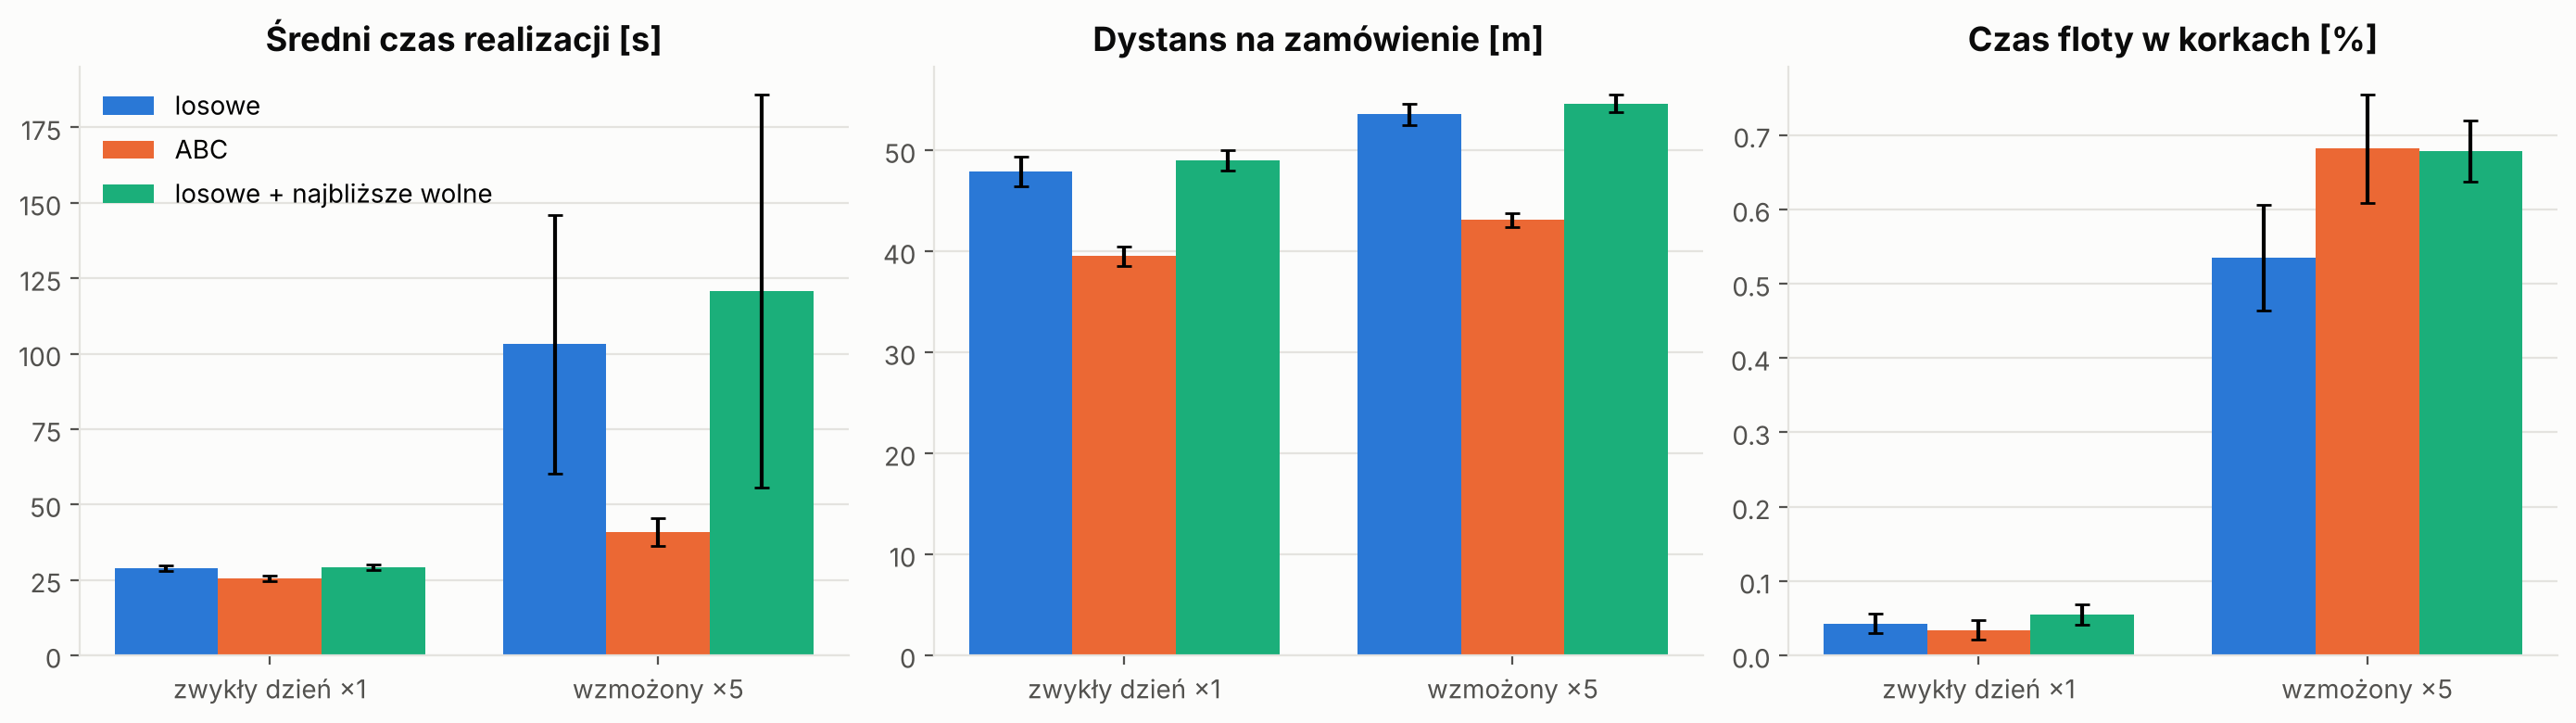

In [3]:
PLACEMENTS = {("random", "home"): "losowe", ("ABC", "home"): "ABC", ("random", "nearest"): "losowe + najbliższe wolne"}
specs = [dict(placement=p, return_policy=rp, volume=v, seed=s)
         for (p, rp) in PLACEMENTS for v in (1.0, 5.0) for s in range(1, 6)]
e1 = run_grid(specs, OUT / "e1_rozmieszczenie.csv", jobs=JOBS)
e1["wariant"] = [PLACEMENTS[(p, rp)] for p, rp in zip(e1.placement, e1.return_policy)]
METRICS = ["avg_completion_s", "max_completion_s", "distance_per_order_m", "traffic_share_pct", "racks_home_pct"]
t1 = summary(e1, ["volume", "wariant"], METRICS)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (metric, title) in zip(axes, [("avg_completion_s", "Średni czas realizacji [s]"),
                                      ("distance_per_order_m", "Dystans na zamówienie [m]"),
                                      ("traffic_share_pct", "Czas floty w korkach [%]")]):
    bars(ax, t1, "volume", "wariant", metric)
    ax.set_title(title)
axes[0].legend()
fig.tight_layout()
fig.savefig(OUT / "e1_rozmieszczenie.png", dpi=150)
t1[["volume", "wariant", "ok", "runs"] + METRICS]

## 2. Ile robotów potrzeba (S1): wzmożony ruch i Black Friday

Średni czas realizacji w zależności od liczby robotów. Przy Black Friday kolejka zamówień rośnie,
a czas realizacji to głównie czekanie na wolnego robota: od pewnej liczby robotów dokładanie
kolejnych pomaga coraz mniej. Przy Black Friday stanowiska są zajęte tylko ok. 50% czasu: wąskim
gardłem jest dojazd do nich (jedno pole wjazdu i wyjazdu, następny robot czeka, aż poprzedni wyjedzie;
`docs/decyzje_dane_olist.md`, sekcja 10).

,volume,placement,num_robots,ok,runs,avg_completion_s,avg_completion_s_ci,avg_wait_for_robot_s,avg_wait_for_robot_s_ci,station_utilisation_pct,station_utilisation_pct_ci,orders_per_hour,orders_per_hour_ci
0,5.0,random,4,3,3,1062.6,7.3,1027.2,7.9,22.0,1.3,232.8,4.7
1,5.0,ABC,4,3,3,849.3,156.4,818.1,156.7,24.2,1.4,256.3,4.6
2,5.0,random,8,3,3,84.6,82.3,48.9,80.8,31.1,3.3,327.6,23.3
3,5.0,ABC,8,3,3,40.0,11.3,8.5,9.5,31.7,2.9,334.7,19.0
4,5.0,random,12,3,3,36.1,3.5,2.4,1.5,31.8,2.9,335.0,18.8
5,5.0,ABC,12,3,3,32.6,4.1,2.1,1.3,31.8,2.9,335.4,18.9
6,5.0,random,16,3,3,34.8,3.3,1.7,0.8,31.8,2.9,335.2,18.9
7,5.0,ABC,16,3,3,31.6,3.7,1.6,0.4,31.8,2.9,335.3,18.8
8,5.0,random,24,3,3,33.8,3.0,1.4,0.3,31.8,2.9,335.2,18.9
9,5.0,ABC,24,3,3,30.7,3.5,1.5,0.3,31.8,2.9,335.4,18.6


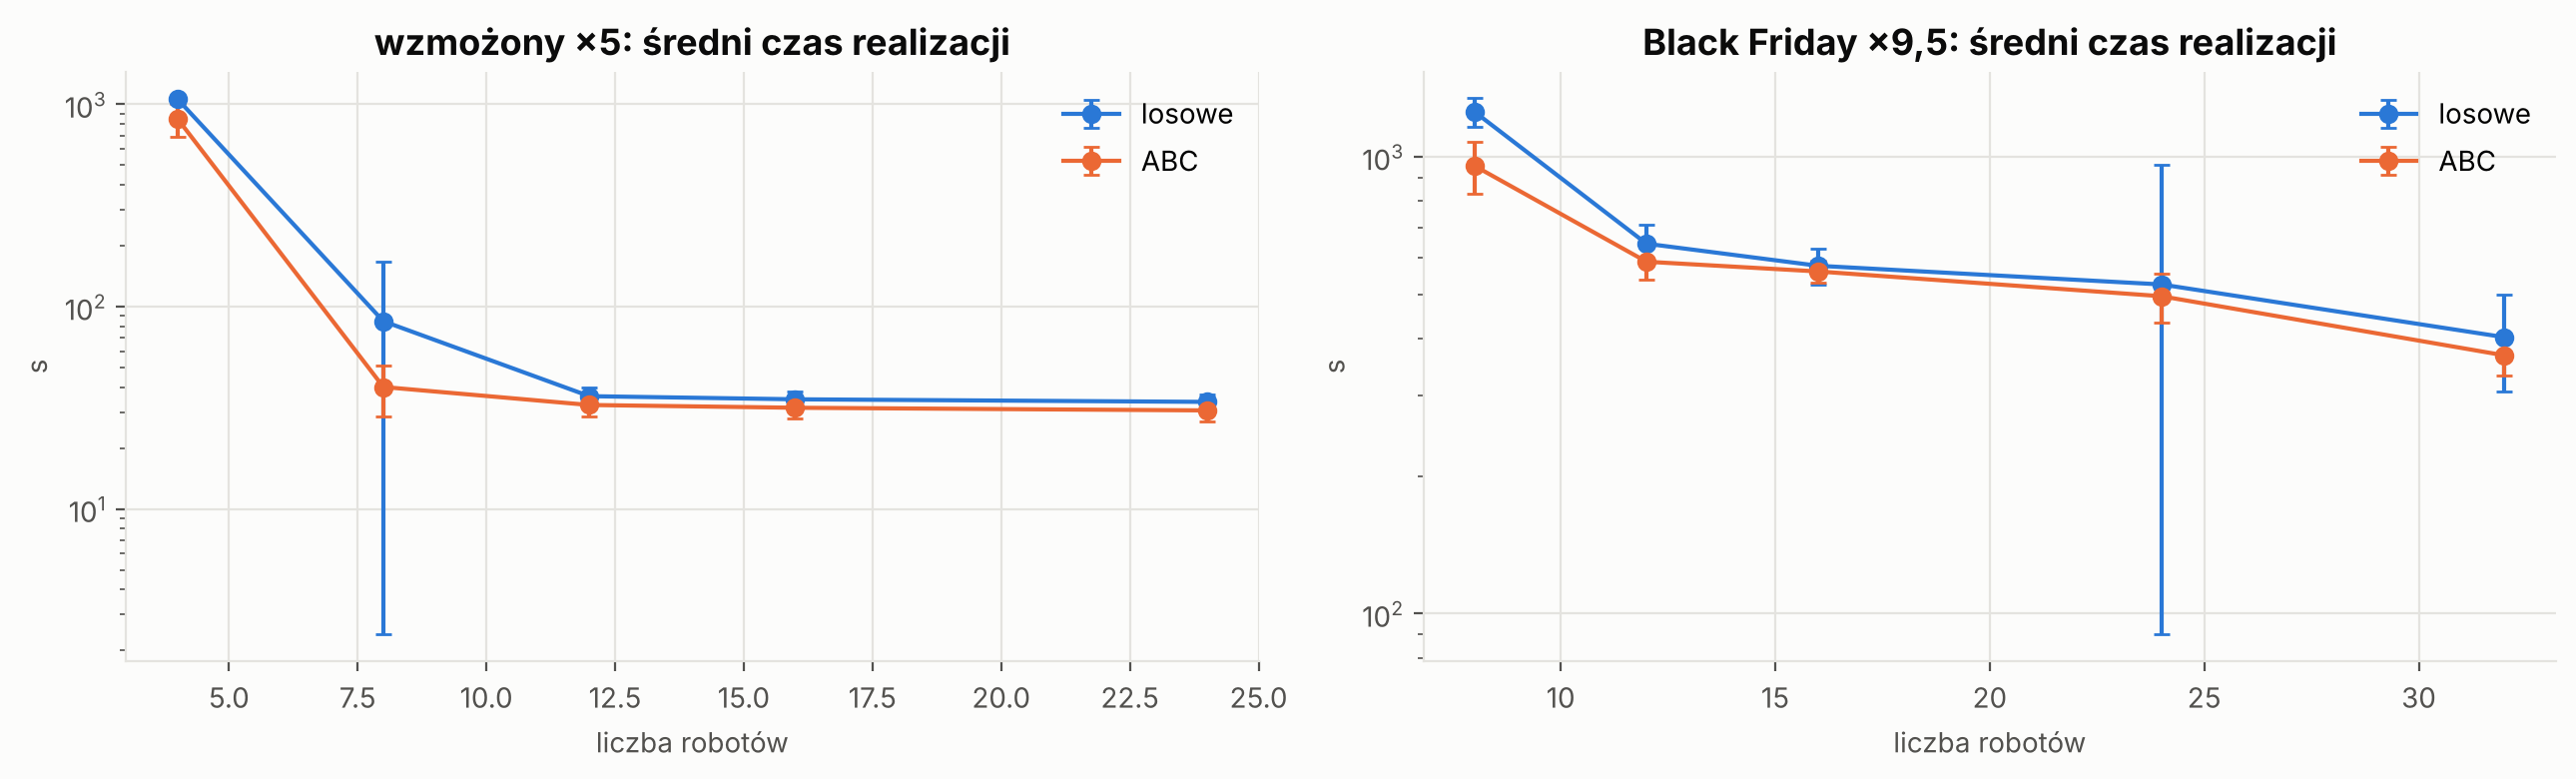

In [4]:
specs = [dict(num_robots=r, placement=p, volume=v, seed=s)
         for v, robots in ((5.0, (4, 8, 12, 16, 24)), (9.5, (8, 12, 16, 24, 32)))
         for r in robots for p in ("random", "ABC") for s in (1, 2, 3)]
e2 = run_grid(specs, OUT / "e2_roboty.csv", jobs=JOBS)
t2 = summary(e2, ["volume", "placement", "num_robots"], ["avg_completion_s", "avg_wait_for_robot_s", "station_utilisation_pct", "orders_per_hour"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, volume in zip(axes, (5.0, 9.5)):
    for color, placement in zip(CATEGORICAL, ("random", "ABC")):
        part = t2[(t2.volume == volume) & (t2.placement == placement)]
        ax.errorbar(part.num_robots, part.avg_completion_s, yerr=part.avg_completion_s_ci,
                    marker="o", capsize=3, color=color, label="losowe" if placement == "random" else "ABC")
    ax.set_title(f"{LOAD[volume]}: średni czas realizacji")
    ax.set_xlabel("liczba robotów")
    ax.set_ylabel("s")
    ax.set_yscale("log")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "e2_roboty.png", dpi=150)
t2

## 3. Przydział zadań (S6): najbliższy robot vs termin i bateria

16 robotów, 5 seedów. `deadline_battery` wybiera robota z uwzględnieniem terminu wysyłki
i poziomu baterii (`src/strategies/assignment.py`).

,volume,assignment,ok,runs,avg_completion_s,avg_completion_s_ci,max_completion_s,max_completion_s_ci,distance_per_order_m,distance_per_order_m_ci
0,5.0,nearest,5,5,35.0,1.2,195.4,71.4,47.1,0.8
1,9.5,nearest,5,5,568.4,26.0,2738.9,695.9,53.4,0.4
2,5.0,deadline_battery,5,5,35.4,1.3,154.4,46.4,47.8,0.8
3,9.5,deadline_battery,5,5,574.3,25.6,2821.3,486.0,54.1,0.6


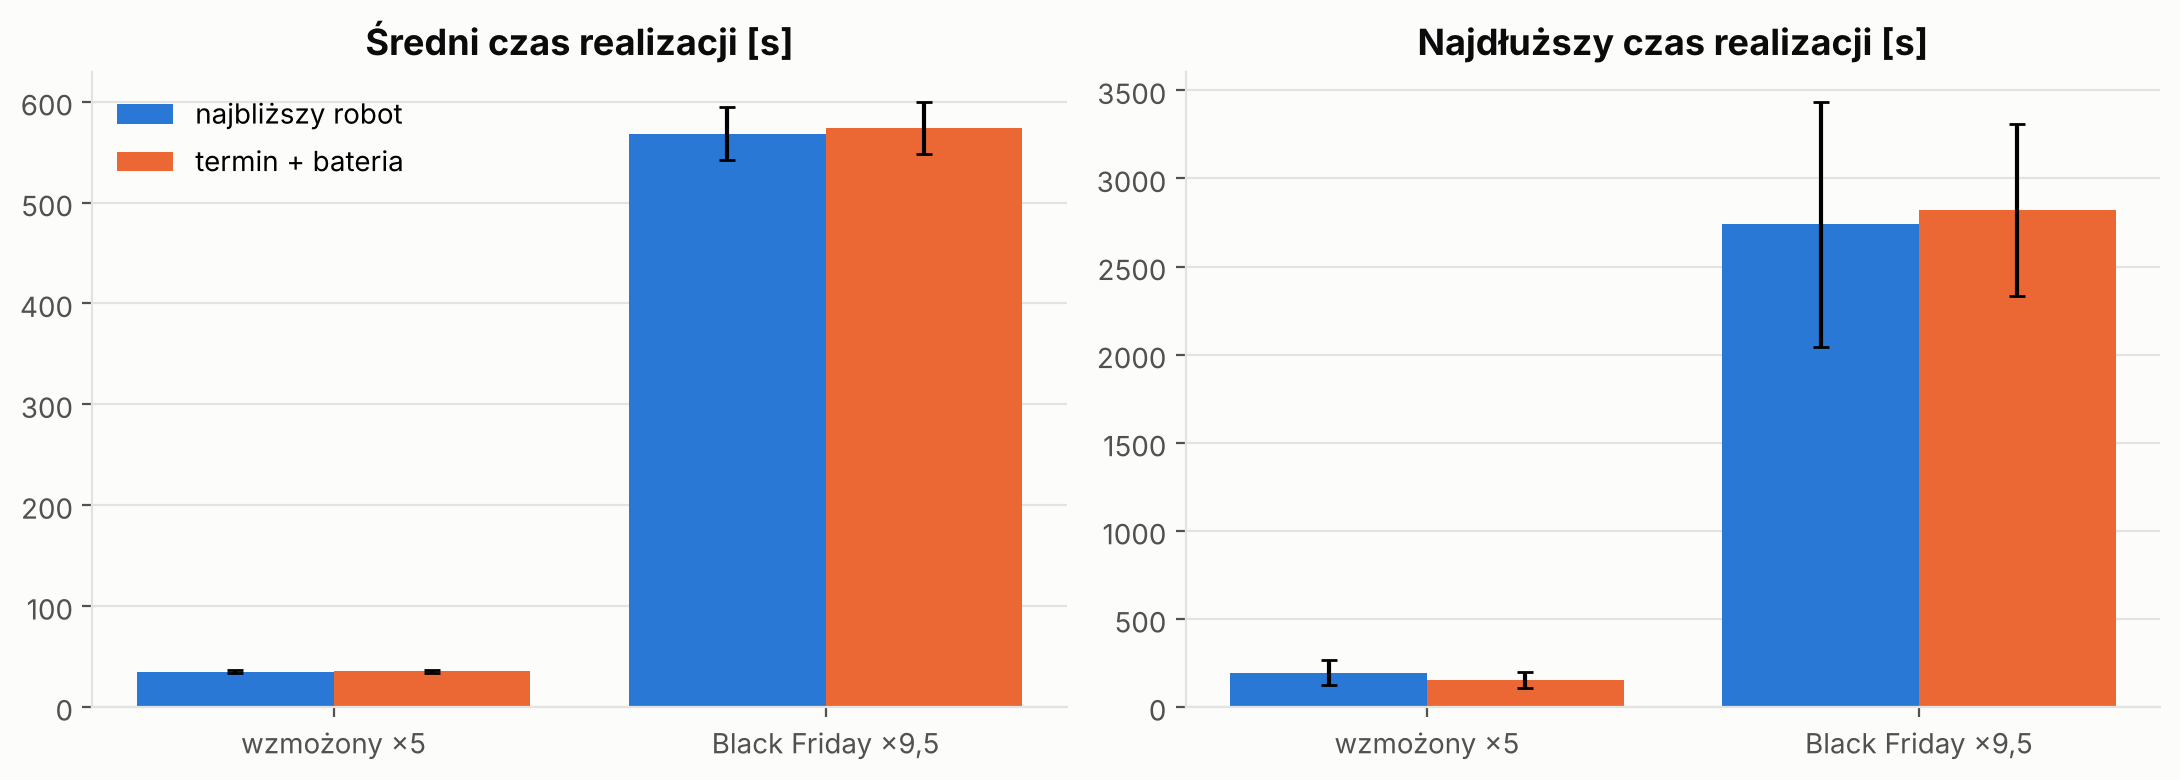

In [5]:
specs = [dict(num_robots=16, assignment=a, volume=v, seed=s)
         for a in ("nearest", "deadline_battery") for v in (5.0, 9.5) for s in range(1, 6)]
e3 = run_grid(specs, OUT / "e3_przydzial.csv", jobs=JOBS)
t3 = summary(e3, ["volume", "assignment"], ["avg_completion_s", "max_completion_s", "distance_per_order_m"])
names = {"nearest": "najbliższy robot", "deadline_battery": "termin + bateria"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (metric, title) in zip(axes, [("avg_completion_s", "Średni czas realizacji [s]"),
                                      ("max_completion_s", "Najdłuższy czas realizacji [s]")]):
    bars(ax, t3, "volume", "assignment", metric, labels=names)
    ax.set_title(title)
axes[0].legend()
fig.tight_layout()
fig.savefig(OUT / "e3_przydzial.png", dpi=150)
t3

## 4. Dodatkowo: układy magazynu (pliki `layouts/*.json`)

Ten sam strumień zamówień (wzmożony ruch ×5), ABC, 8 robotów, 3 seedy. Magazyny różnią się liczbą
regałów i stanowisk, więc to porównanie geometrii hali, a nie jednej zmiennej. Żeby było widać, ile
wynika z samej odległości, tabela ma też liczbę regałów i stanowisk oraz średni dojazd regał →
najbliższe stanowisko w polach (`rack_to_station_cells`, `layout_geometry` w `src/experiments/compare.py`).
W temacie projektu tego nie ma; do decyzji z prowadzącym, czy włączać.

Układ `dwie_hale` został poprawiony 23.11: wcześniej środkowa hala miała 17 pól szerokości, a stanowiska
stały w jej dolnej ścianie przesunięte w lewo, więc każdy regał jechał przez pusty przedsionek
(średni dojazd 17,6 pola, przy ×5 średni czas 160 s i 58,7 m na zamówienie, 10 seedów). Teraz strefa
kompletacji ma 5 pól, stanowiska stoją symetrycznie przy dolnym przejściu (14,6 pola; 57 s i 48,7 m).
Szczegóły: `docs/decyzje_dane_olist.md`, sekcja 12.


,layout,racks,stations,rack_to_station_cells,ok,runs,avg_completion_s,avg_completion_s_ci,distance_per_order_m,traffic_share_pct,station_utilisation_pct
0,demo_20x20,144,2,12.7,3,3,35.0,9.3,37.5,1.2,31.7
1,dwie_hale,96,3,14.6,3,3,47.0,21.5,48.2,1.0,20.8
2,hala_L,112,3,13.1,3,3,28.7,3.1,34.8,0.7,21.2
3,kiva_standard,160,2,16.5,3,3,40.0,11.3,42.9,0.7,31.7
4,szerokie_alejki,120,3,17.9,3,3,29.4,3.6,37.2,0.4,21.2


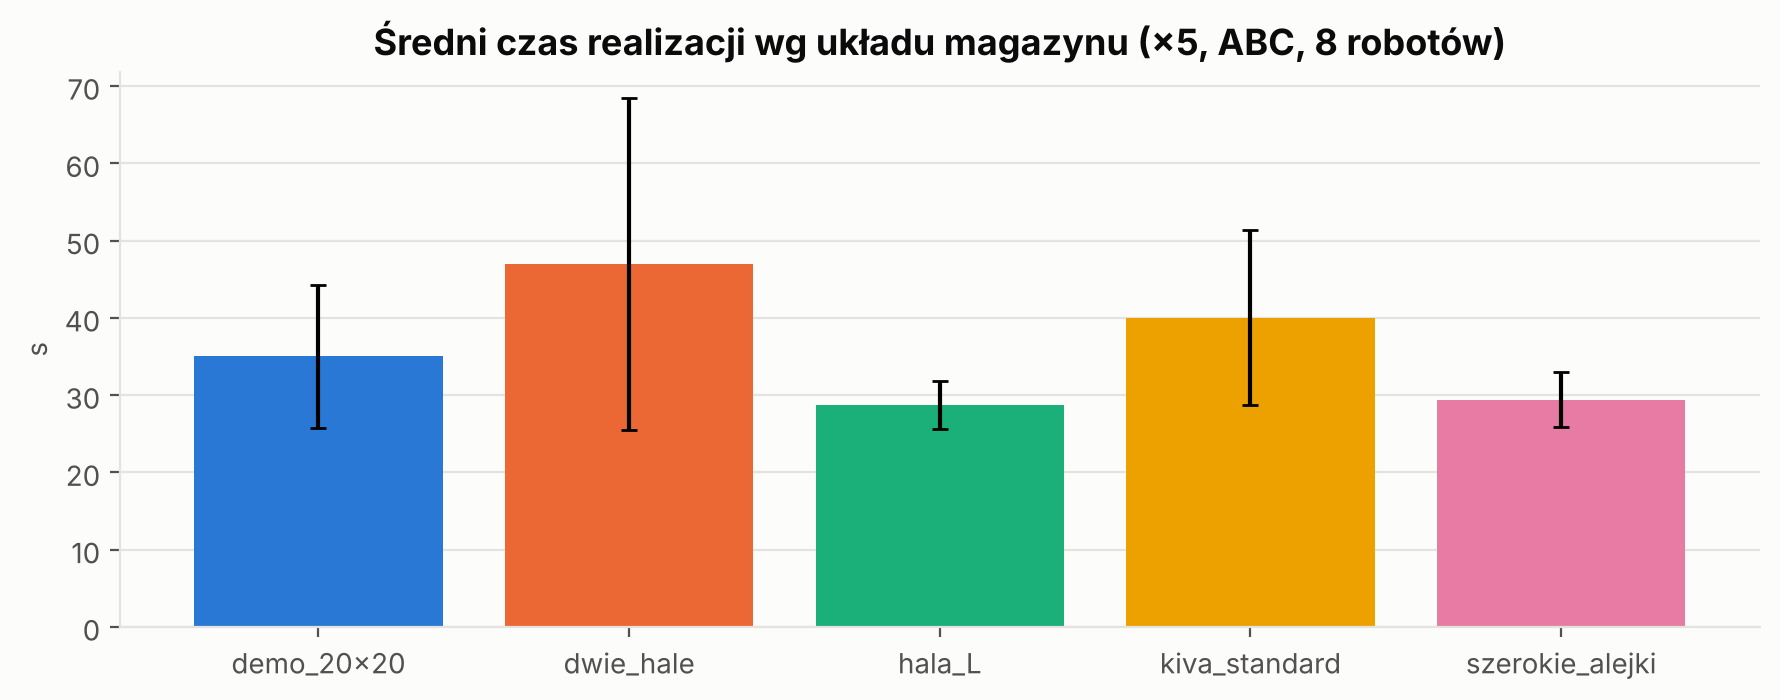

In [6]:
specs = [dict(layout=key, placement="ABC", volume=5.0, seed=s) for key in LAYOUTS for s in (1, 2, 3)]
e4 = run_grid(specs, OUT / "e4_uklady.csv", jobs=JOBS)
t4 = summary(e4, ["layout"], ["avg_completion_s", "distance_per_order_m", "traffic_share_pct", "station_utilisation_pct"])
# Geometria: ile regałów i stanowisk oraz średni dojazd regał → najbliższe stanowisko (w polach),
# żeby było widać, co wynika z ruchu, a co z samej odległości.
geo4 = pd.DataFrame([{"layout": k, **layout_geometry(LAYOUTS[k].layout)} for k in t4.layout])
t4 = t4.merge(geo4, on="layout")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(t4.layout, t4.avg_completion_s, yerr=t4.avg_completion_s_ci, capsize=3, color=CATEGORICAL[: len(t4)])
ax.set_ylabel("s")
ax.set_title("Średni czas realizacji wg układu magazynu (×5, ABC, 8 robotów)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT / "e4_uklady.png", dpi=150)
t4[["layout", "racks", "stations", "rack_to_station_cells", "ok", "runs", "avg_completion_s", "avg_completion_s_ci",
    "distance_per_order_m", "traffic_share_pct", "station_utilisation_pct"]]

## 5. Która reguła ruchu ile daje (wyłączanie po jednej)

Pytanie z zespołu: czy np. przejazd pustych robotów pod regałami to tylko „łatka” na zakleszczenia,
czy cenna informacja, że warto coś takiego mieć w magazynie. Dlatego każdą regułę z `TrafficParams`
wyłączamy osobno, a resztę zostawiamy (`traffic="no_<reguła>"`, `TRAFFIC_VARIANTS` w
`src/experiments/build.py`). 16 robotów przy każdym natężeniu (ta sama flota, więc punkty da się porównać), 10 seedów, 4 h.

Patrzymy na dwie rzeczy naraz, bo wyłączenie reguły może zarówno zatrzymać magazyn (zakleszczenie),
jak i tylko go spowolnić:

* lewy wykres: odsetek przebiegów zatrzymanych przez zakleszczenie,
* prawy wykres: średni czas realizacji przy ×5, liczony **tylko z przebiegów bez zakleszczenia**
  (napis „stoi” = wszystkie przebiegi się zakleszczyły, więc nie ma czego uśredniać).

Uwaga przy interpretacji: w prawdziwych magazynach typu Kiva roboty z konstrukcji jeżdżą pod
regałami. Wynik „bez przejazdu pod regałami” mówi więc, ile traci magazyn, w którym to niemożliwe
(inny typ robotów, za niskie regały), a nie czy to „wdrażać”.

,volume,reguła,zakleszczenia_pct,ok,runs,avg_completion_s,max_completion_s,distance_per_order_m,avg_station_queue_s
0,1.0,wszystkie reguły,0.0,10,10,27.5,66.6,46.2,1.0
3,1.0,bez przejazdu pod regałami,0.0,10,10,37.9,126.4,59.6,1.0
6,1.0,bez kierunków w alejkach i kosztów pól,0.0,10,10,24.2,65.5,38.7,1.3
9,1.0,bez limitu kolejki do stanowiska,0.0,10,10,27.5,67.0,46.2,1.0
12,1.0,bez wolnego pola przed stanowiskiem,0.0,10,10,28.0,73.6,46.7,1.4
15,1.0,bez omijania stojących robotów,0.0,10,10,27.5,66.2,46.2,1.0
18,1.0,bez wyboru najbliższego stanowiska,0.0,10,10,28.5,67.4,49.8,0.5
21,1.0,bez zjazdu z ładowarki,0.0,10,10,27.5,66.6,46.2,1.0
24,1.0,żadnej reguły (stan sprzed poprawki),20.0,8,10,26.9,94.0,44.9,0.7
1,5.0,wszystkie reguły,0.0,10,10,35.0,202.1,47.2,4.4


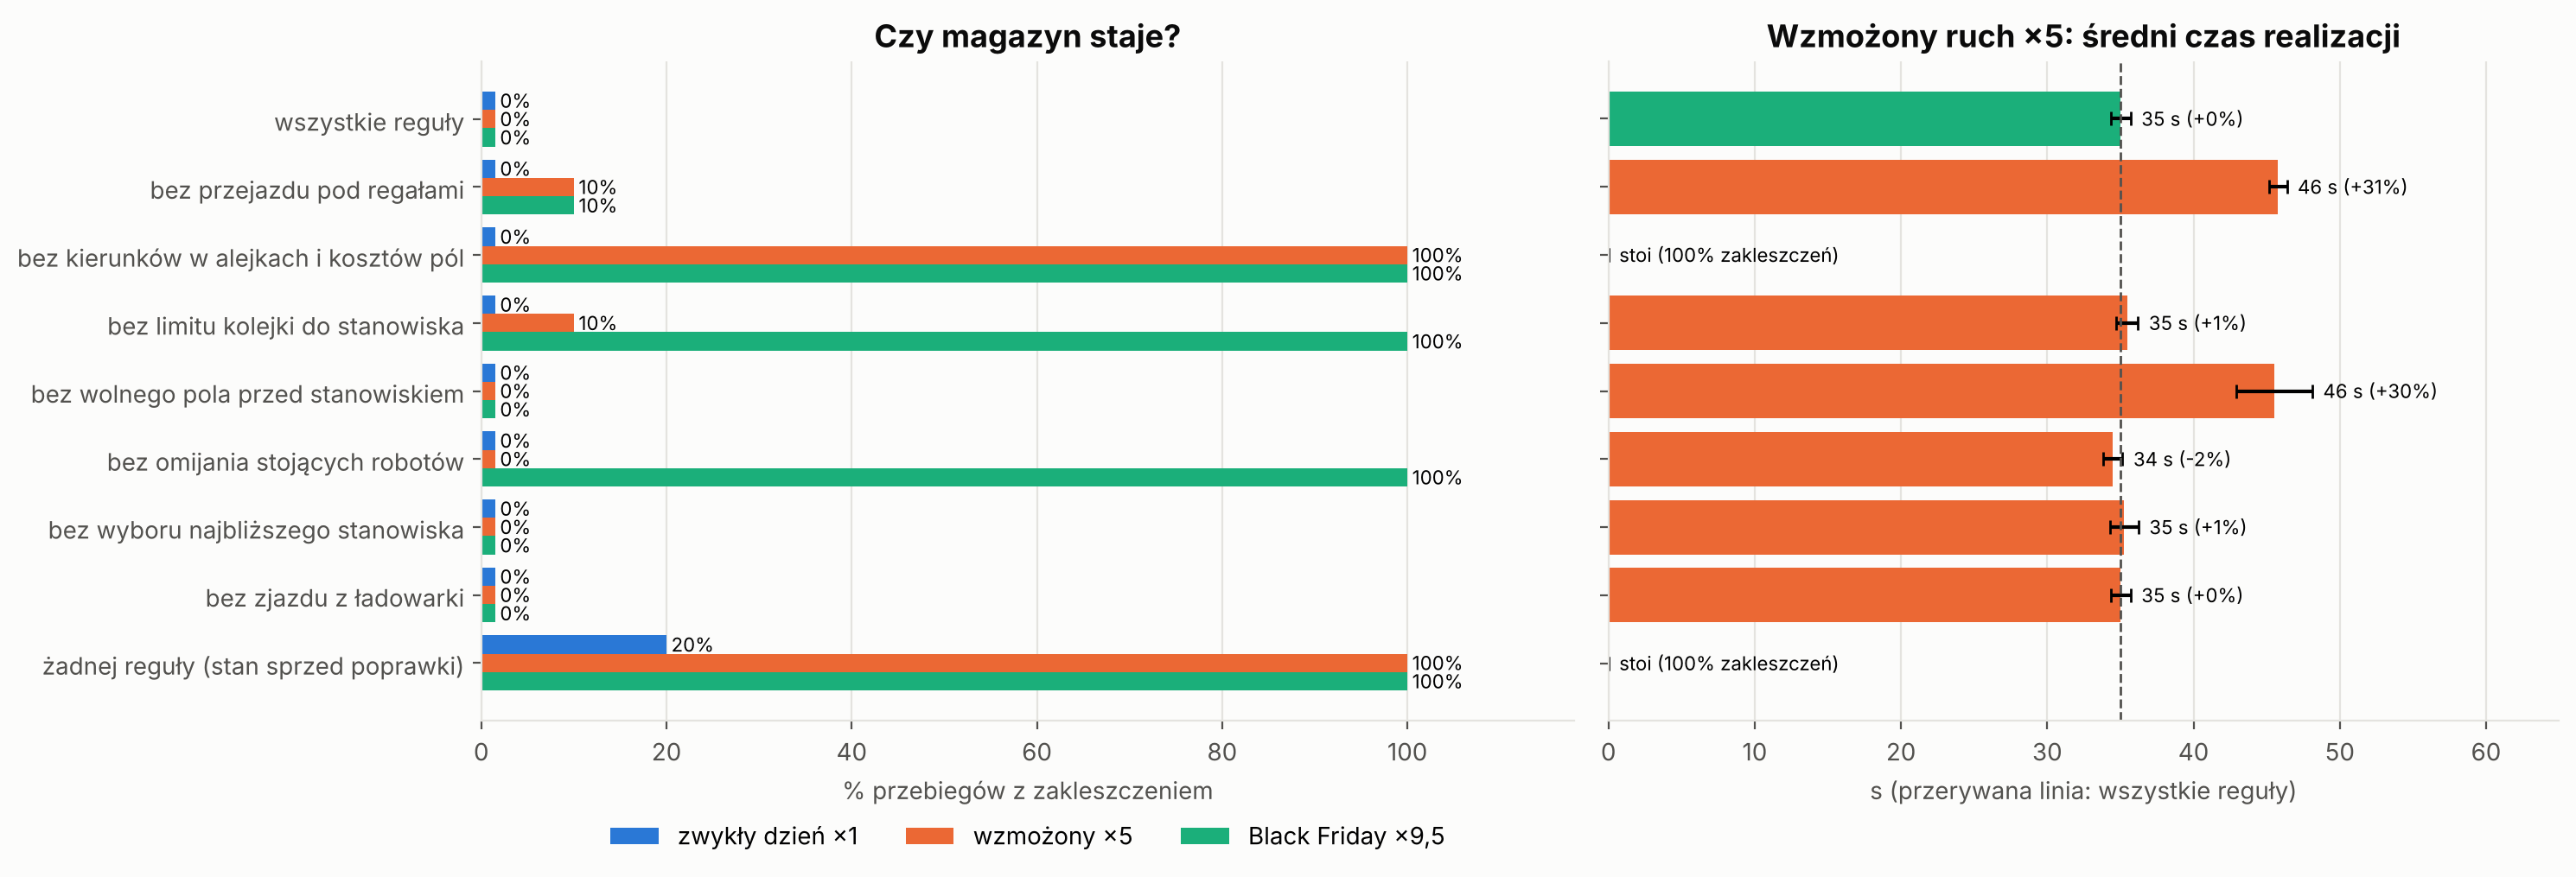

In [7]:
RULES = {
    "new": "wszystkie reguły",
    "no_under_racks": "bez przejazdu pod regałami",
    "no_route_costs": "bez kierunków w alejkach i kosztów pól",
    "no_queue_limit": "bez limitu kolejki do stanowiska",
    "no_front_free": "bez wolnego pola przed stanowiskiem",
    "no_replan": "bez omijania stojących robotów",
    "no_nearest_station": "bez wyboru najbliższego stanowiska",
    "no_leave_charger": "bez zjazdu z ładowarki",
    "old": "żadnej reguły (stan sprzed poprawki)",
}
specs = [dict(num_robots=r, volume=v, seed=s, traffic=t)
         for t in RULES for (r, v) in ((16, 1.0), (16, 5.0), (16, 9.5)) for s in range(1, 11)]
e5 = run_grid(specs, OUT / "e5_reguly.csv", jobs=JOBS)
e5["zakleszczenie"] = e5["status"].isin(["deadlock", "livelock"])
dl5 = e5.groupby(["traffic", "volume"])["zakleszczenie"].mean().mul(100).unstack(1).reindex(list(RULES))
t5 = summary(e5, ["volume", "traffic"], ["avg_completion_s", "max_completion_s", "distance_per_order_m",
                                          "avg_station_queue_s", "traffic_share_pct"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
y = np.arange(len(RULES))
labels = [RULES[k] for k in RULES]
for i, v in enumerate((1.0, 5.0, 9.5)):
    drawn = ax1.barh(y + (i - 1) * 0.27, dl5[v].clip(lower=1.5), 0.27, color=CATEGORICAL[i], label=LOAD[v])
    ax1.bar_label(drawn, labels=[f"{x:.0f}%" for x in dl5[v]], padding=2, fontsize=8)
ax1.set_yticks(y, labels)
ax1.invert_yaxis()
ax1.set_xlim(0, 118)
ax1.set_xlabel("% przebiegów z zakleszczeniem")
ax1.set_title("Czy magazyn staje?")
ax1.grid(axis="y", visible=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)

part = t5[t5.volume == 5.0].set_index("traffic").reindex(list(RULES))
base = part.loc["new", "avg_completion_s"]
ax2.barh(y, part.avg_completion_s.fillna(0), xerr=part.avg_completion_s_ci.fillna(0), capsize=3,
         color=[CATEGORICAL[2] if k == "new" else CATEGORICAL[1] for k in RULES])
ax2.axvline(base, color=INK_SECONDARY, lw=1, ls="--")
for yy, k in zip(y, RULES):
    value, ci = part.loc[k, "avg_completion_s"], part.loc[k, "avg_completion_s_ci"]
    text = "stoi (100% zakleszczeń)" if pd.isna(value) else f"{value:.0f} s ({100 * (value - base) / base:+.0f}%)"
    # Podpis za końcem paska błędu, żeby się nie nakładały.
    ax2.text(0 if pd.isna(value) else value + (0 if pd.isna(ci) else ci), yy, "  " + text, va="center", fontsize=8)
ax2.set_yticks(y, [""] * len(y))
ax2.invert_yaxis()
ax2.set_xlim(0, (part.avg_completion_s + part.avg_completion_s_ci.fillna(0)).max() * 1.35)
ax2.set_xlabel("s (przerywana linia: wszystkie reguły)")
ax2.set_title("Wzmożony ruch ×5: średni czas realizacji")
ax2.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(OUT / "e5_reguly.png", dpi=150)

table5 = t5.assign(reguła=t5.traffic.map(RULES), zakleszczenia_pct=[dl5.loc[t, v] for t, v in zip(t5.traffic, t5.volume)])
table5[["volume", "reguła", "zakleszczenia_pct", "ok", "runs", "avg_completion_s", "max_completion_s",
        "distance_per_order_m", "avg_station_queue_s"]].sort_values(["volume"], kind="stable")

**Co z tego wynika** (16 robotów przy każdym natężeniu, 10 seedów, 4 h; liczby z tabeli powyżej):

* **Przejazd pod regałami skraca trasy, a bez niego magazyn rzadko, ale czasem staje.** Bez tej
  reguły dystans na zamówienie rośnie o ok. 29% (×1), 26% (×5) i 16% (×9,5), a średni czas realizacji
  o ok. 38% (×1) i 31% (×5), bo puste roboty objeżdżają regały alejkami. Zakleszczenia: 0% przy ×1,
  10% przy ×5 i ×9,5 (po 1 z 10). To reguła o znaczeniu praktycznym: wycenia robota mieszczącego się
  pod regałem.
* **Uwaga do wcześniejszej wersji tego wykresu** (60% zakleszczeń przy ×1, 20% przy ×5, 40% przy
  ×9,5): odwrócona kolejność była błędem modelu, nie cechą magazynu. Bez przejazdu pod regałami
  bezczynny robot ustępował miejsca do pustego slotu po zabranym regale albo zostawał pod regałem,
  który właśnie odstawił. Slot to ślepa kieszeń między regałami, a robot, który przyjeżdżał po ten
  regał, stawał w jedynym wyjeździe. Przy ×1 roboty częściej są bezczynne, więc błąd zdarzał się
  częściej. Do tego punkty nie były porównywalne (8 robotów przy ×1 i ×5, 16 przy ×9,5) i było tylko
  5 seedów. Poprawka: reguła `leave_rack_slots` w `TrafficParams` (sekcja 12 w
  `docs/decyzje_dane_olist.md`).
* **Kierunki w alejkach (z kosztami pól) to cena za brak zakleszczeń.** Przy zwykłym dniu bez nich
  jest szybciej (dystans −16%, czas −12%), bo roboty jadą najkrótszą drogą, ale od ×5 wzwyż każdy
  przebieg staje. Przy małym ruchu reguła kosztuje, przy dużym jest konieczna.
* **Limit kolejki i omijanie stojących robotów** przy ×1 i ×5 prawie nic nie zmieniają (bez limitu
  1 zakleszczenie na 10 przy ×5), ale bez każdej z nich Black Friday zawsze się zakleszcza.
  To reguły „na szczyt”.
* **Wolne pole przed stanowiskiem** nie chroni przed zakleszczeniem, tylko przyspiesza: bez niego
  średni czas rośnie o ok. 30% przy ×5 i 61% przy Black Friday. **Wybór najbliższego stanowiska**
  daje mniej: +1% przy ×5, +7% przy ×9,5, za to dystans rośnie o 7–8%.
* **Zjazd z ładowarki** nie zmienia wyniku w tych 4-godzinnych przebiegach (wyniki są co do sekundy
  takie same, więc reguła w tym czasie nie zadziałała). Ma znaczenie dopiero w dłuższych przebiegach.
* **Żadnej reguły** (stan sprzed poprawki) zakleszcza się już w zwykły dzień (2 z 10), a od ×5 zawsze.


## 6. Najważniejsze różnice w liczbach

Liczone z tabel powyżej (średnie po seedach, tylko przebiegi bez zakleszczenia).

In [8]:
def change(table, by, base, other, metric, **where):
    part = table
    for key, value in where.items():
        part = part[part[key] == value]
    a = part[part[by] == base][metric].iloc[0]
    b = part[part[by] == other][metric].iloc[0]
    return f"{a:.1f} → {b:.1f} ({100 * (b - a) / a:+.0f}%)"

rows = []
for v in (1.0, 5.0):
    for metric, name in [("avg_completion_s", "średni czas [s]"), ("distance_per_order_m", "dystans/zam. [m]"),
                         ("traffic_share_pct", "korki [% czasu floty]")]:
        rows.append({"porównanie": f"losowe → ABC, {LOAD[v]}", "miara": name,
                     "zmiana": change(t1, "wariant", "losowe", "ABC", metric, volume=v)})
for v in (5.0, 9.5):
    rows.append({"porównanie": f"najbliższy → termin+bateria, {LOAD[v]}", "miara": "średni czas [s]",
                 "zmiana": change(t3, "assignment", "nearest", "deadline_battery", "avg_completion_s", volume=v)})
pd.DataFrame(rows)

,porównanie,miara,zmiana
0,"losowe → ABC, zwykły dzień ×1",średni czas [s],28.8 → 25.6 (-11%)
1,"losowe → ABC, zwykły dzień ×1",dystans/zam. [m],47.9 → 39.5 (-17%)
2,"losowe → ABC, zwykły dzień ×1",korki [% czasu floty],0.0 → 0.0 (-20%)
3,"losowe → ABC, wzmożony ×5",średni czas [s],103.1 → 40.8 (-60%)
4,"losowe → ABC, wzmożony ×5",dystans/zam. [m],53.6 → 43.1 (-20%)
5,"losowe → ABC, wzmożony ×5",korki [% czasu floty],0.5 → 0.7 (+28%)
6,"najbliższy → termin+bateria, wzmożony ×5",średni czas [s],35.0 → 35.4 (+1%)
7,"najbliższy → termin+bateria, Black Friday ×9,5",średni czas [s],568.4 → 574.3 (+1%)
